# Generative neural networks for the sciences - Exercise 2

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.mixture import GaussianMixture

## 1. Create two-moons dataset

In [2]:
# Noise level 0.1 for initial tasks
X_train_01, _ = make_moons(n_samples=2000, noise=0.1, random_state=42)
X_test_01, _ = make_moons(n_samples=500, noise=0.1, random_state=42)

## 2. Build the autoencoder

In [3]:
class Autoencoder(nn.Module):
    def __init__(self, input_size=2, bottleneck_size=1, hidden_size=16, layers=2):
        super(Autoencoder, self).__init__()
        
        # Encoder: Linear + ReLU for interior, Linear for output
        encoder_modules = []
        current_dim = input_size
        for _ in range(layers):
            encoder_modules.append(nn.Linear(current_dim, hidden_size))
            encoder_modules.append(nn.ReLU())
            current_dim = hidden_size
        encoder_modules.append(nn.Linear(hidden_size, bottleneck_size))
        self.encoder = nn.Sequential(*encoder_modules)
        
        # Decoder: Mirror of encoder
        decoder_modules = []
        current_dim = bottleneck_size
        for _ in range(layers):
            decoder_modules.append(nn.Linear(current_dim, hidden_size))
            decoder_modules.append(nn.ReLU())
            current_dim = hidden_size
        decoder_modules.append(nn.Linear(hidden_size, input_size))
        self.decoder = nn.Sequential(*decoder_modules)

    def forward(self, x):
        return self.decoder(self.encoder(x))
    
    def encode(self, x):
        return self.encoder(x)
    
    def decode(self, code):
        return self.decoder(code)

## 3. Train the autoencoder

In [ ]:
def train_autoencoder(model, data, batch_size=32, epochs=50, lr=0.001):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    
    tensor_data = torch.FloatTensor(data)
    dataset = torch.utils.data.TensorDataset(tensor_data)
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
    epoch_losses = []
    for epoch in range(epochs):
        batch_losses = []
        for batch in dataloader:
            x_batch = batch[0]
            
            optimizer.zero_grad()
            reconstructed = model(x_batch)
            loss = criterion(reconstructed, x_batch)
            loss.backward()
            optimizer.step()
            
            batch_losses.append(loss.item())
            
        epoch_losses.append(np.mean(batch_losses))
        
    return epoch_losses

## 4. Investigate hyperparameters

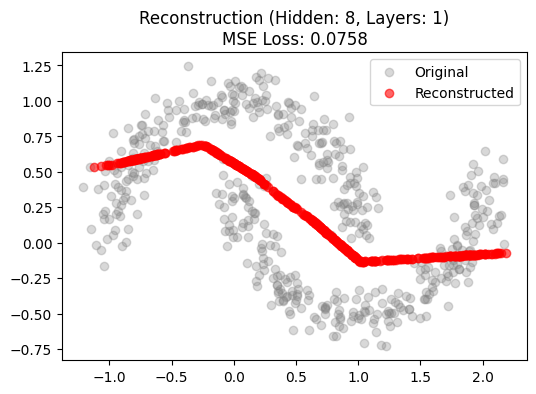

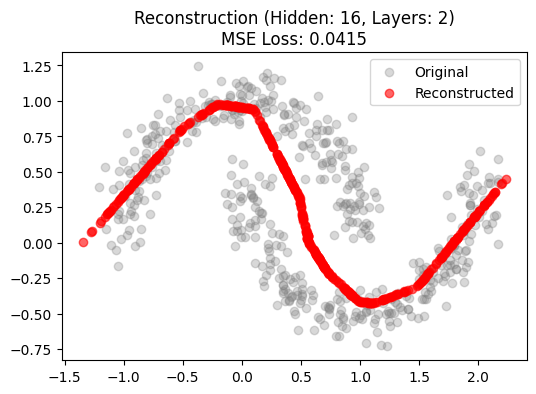

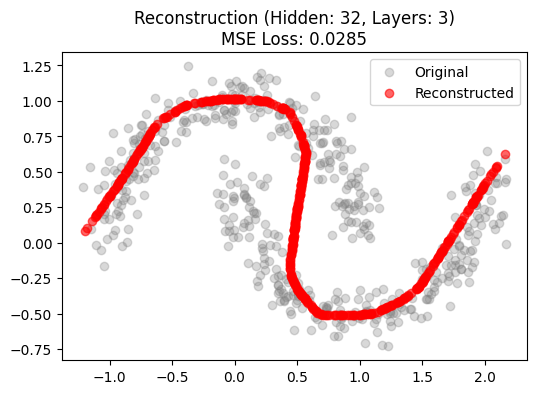

Best Hyperparameters -> hidden_size: 32, layers: 2


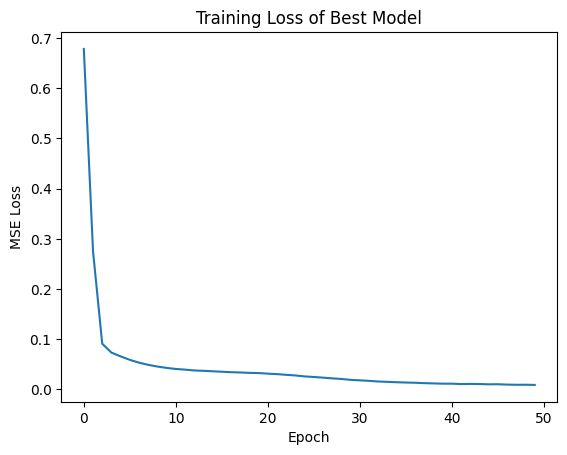

In [6]:
hidden_sizes = [8, 16, 32]
layer_counts = [1, 2, 3]
hp_results = {}

for hs in hidden_sizes:
    for lc in layer_counts:
        model = Autoencoder(hidden_size=hs, layers=lc)
        # Train lightly for rapid evaluation
        train_autoencoder(model, X_train_01, epochs=20) 
        
        with torch.no_grad():
            recon = model(torch.FloatTensor(X_test_01))
            test_loss = nn.MSELoss()(recon, torch.FloatTensor(X_test_01)).item()
            
        hp_results[(hs, lc)] = test_loss
        
        # Plot reconstruction vs original for a subset of hyperparameter combinations
        subset_to_plot = [(8, 1), (16, 2), (32, 3)]
        
        if (hs, lc) in subset_to_plot:
            # Convert the PyTorch tensor back to a NumPy array for matplotlib
            recon_np = recon.numpy() 
            
            plt.figure(figsize=(6, 4))
            # Plot the original two-moons test data as a faded background
            plt.scatter(X_test_01[:, 0], X_test_01[:, 1], alpha=0.3, color="gray", label="Original")
            # Overlay the model's reconstruction
            plt.scatter(recon_np[:, 0], recon_np[:, 1], alpha=0.6, color="red", label="Reconstructed")
            
            # Label the plot with the current hyperparameters and loss
            plt.title(f"Reconstruction (Hidden: {hs}, Layers: {lc})\nMSE Loss: {test_loss:.4f}")
            plt.legend()
            plt.show()
        
best_hp = min(hp_results, key=hp_results.get)
best_hs, best_lc = best_hp
print(f"Best Hyperparameters -> hidden_size: {best_hs}, layers: {best_lc}")

# Train the optimal model fully for the rest of the steps
best_model = Autoencoder(hidden_size=best_hs, layers=best_lc)
best_model_losses = train_autoencoder(best_model, X_train_01, epochs=50)

plt.plot(best_model_losses)
plt.title("Training Loss of Best Model")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.show()

## 5. Repeat training experiments

In [ ]:
print("5. Evaluating Training Variance...")
# TODO: Initialize and train a few models using best_hs and best_lc on X_train_01 to observe variance.
# TODO: Generate 3-5 new datasets with make_moons(noise=0.1) and train a new model on each to evaluate data variance.

## 6. Analyze the latent code

In [ ]:
print("6. Extracting and Analyzing Latent Codes...")
with torch.no_grad():
    latent_codes = best_model.encode(torch.FloatTensor(X_train_01)).numpy()
    
plt.figure(figsize=(6, 4))
plt.hist(latent_codes, bins=50, density=True, alpha=0.7, color='blue')
plt.title("Histogram of Bottleneck Codes")
plt.xlabel("Latent Space (1D)")
plt.ylabel("Density")
plt.show()

## 7. Fit a GMM and generate samples

In [ ]:
print("7. Fitting GMM and Generating Synthetic Data...")
# Fit the 1D GMM to the latent codes
gmm = GaussianMixture(n_components=5, random_state=42)
gmm.fit(latent_codes)

# Sample new synthetic latent codes
synthetic_codes, _ = gmm.sample(500)

with torch.no_grad():
    # Decode them back to 2D
    synthetic_2d = best_model.decode(torch.FloatTensor(synthetic_codes)).numpy()
    
plt.figure(figsize=(6, 4))
plt.scatter(synthetic_2d[:, 0], synthetic_2d[:, 1], alpha=0.5, color='green')
plt.title("Decoded Synthetic Points from GMM")
plt.show()

## 8. Test on noise 0.2 without retraining

In [ ]:
print("8. Testing Out-of-Distribution (Noise 0.2)...")
with torch.no_grad():
    recon_02_original_model = best_model(torch.FloatTensor(X_test_02)).numpy()

# TODO: Plot X_test_02 alongside recon_02_original_model to visually inspect performance
plt.figure(figsize=(6, 4))
plt.scatter(X_test_02[:, 0], X_test_02[:, 1], alpha=0.3, label="Original (0.2 Noise)")
plt.scatter(recon_02_original_model[:, 0], recon_02_original_model[:, 1], alpha=0.5, label="Reconstructed")
plt.title("Best Model (Trained on 0.1) Tested on 0.2 Noise")
plt.legend()
plt.show()

## 9. Retrain on noise 0.2

In [ ]:
print("9. Retraining Model on Noise 0.2 Data...")
model_02 = Autoencoder(hidden_size=best_hs, layers=best_lc)
train_autoencoder(model_02, X_train_02, epochs=50)

with torch.no_grad():
    recon_02_retrained = model_02(torch.FloatTensor(X_test_02)).numpy()
    
# TODO: Compare the geometry of recon_02_retrained with recon_02_original_model 
plt.figure(figsize=(6, 4))
plt.scatter(X_test_02[:, 0], X_test_02[:, 1], alpha=0.3, label="Original (0.2 Noise)")
plt.scatter(recon_02_retrained[:, 0], recon_02_retrained[:, 1], alpha=0.5, label="Reconstructed")
plt.title("Retrained Model Tested on 0.2 Noise")
plt.legend()
plt.show()